# Benchmark Comparison Results and False-Alarm Plots

This notebook loads the saved metrics for KALEIDO and the benchmark detectors, aggregates them across runs, and generates two figures:

- `figures/results_v3.pdf` compares precision, recall, F1 score, and detection-delay metrics across time series.
- `figures/false_alarms_no_drift.pdf` compares false-alarm counts on the no-drift Friedman streams.

In [1]:
from pathlib import Path as _Path
import os as _os

for _candidate in (_Path.cwd(), *_Path.cwd().parents):
    if (_candidate / "KALEIDO_multi_instance.py").is_file() and (_candidate / "stable_windows.csv").is_file():
        _code_dir = _candidate
        break
    _nested = _candidate / "results_all_in_one_code"
    if (_nested / "KALEIDO_multi_instance.py").is_file() and (_nested / "stable_windows.csv").is_file():
        _code_dir = _nested
        break
else:
    raise FileNotFoundError("Could not locate results_all_in_one_code; start this notebook inside the repository")

_os.chdir(_code_dir)
(_code_dir / "figures").mkdir(exist_ok=True)
(_code_dir / "example_runs").mkdir(exist_ok=True)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
from matplotlib.lines import Line2D


# Functions

In [2]:
def std_upper(x):
    m = x.mean()
    above_mean = x[x >= m]
    ddof = 0
    N = len(above_mean)
    if N <= ddof: # to avoid devision by 0
        return np.nan
    
    var = (abs(above_mean - m)**2).sum() / (N - ddof)  # note use of `ddof`
    return var**0.5

def std_lower(x):
    m = x.mean()
    below_mean = x[x < m]
    ddof = 0
    N = len(below_mean)
    if N <= ddof: # to avoid devision by 0
        return np.nan
    
    var = (abs(below_mean - m)**2).sum() / (N - ddof)  # note use of `ddof`
    return var**0.5


# Data loading

In [3]:
metric_cols = [
    'True Positives', 'False Positives', 'Precision', 'Recall', 'F1 Score',
    'Miss Detection Rate', 'False Positive Rate',
    'Sum Late Detections', 'Sum Early Detections',
    'Sum Both Early and Late Detections',
    'Sum Late Detections end', 'Sum Early Detections end', 'Sum Both Early and Late Detections end'
]

## Season and gradient test

In [4]:
df_proposal_s_gradient = pd.read_csv("../results_all_in_one_code/config_all_trans_1_data_only/season+gradient/final/metrics_proposal_100_configs_config_all_trans_1_data_only_season+gradient_stable_window.csv")
df_proposal_s_gradient_ts = (
    df_proposal_s_gradient
    .groupby(['time_series', 'config'])
    .agg(
        n_samples=('id', 'count'),
        **{f'{c}_mean': (c, 'mean') for c in metric_cols},
        **{f'{c}_std': (c, 'std') for c in metric_cols},
        **{f'{c}_std_up': (c, std_upper) for c in metric_cols},
        **{f'{c}_std_low': (c, std_lower) for c in metric_cols},
        # stat_value range info
        stat_value_min=('stat_value', 'min'),
        stat_value_max=('stat_value', 'max'),
        stat_value_range=('stat_value', lambda x: x.max() - x.min())
    )
    .reset_index()
)
df_proposal_s_gradient_ts

,time_series,config,n_samples,True Positives_mean,False Positives_mean,Precision_mean,Recall_mean,F1 Score_mean,Miss Detection Rate_mean,False Positive Rate_mean,...,False Positive Rate_std_low,Sum Late Detections_std_low,Sum Early Detections_std_low,Sum Both Early and Late Detections_std_low,Sum Late Detections end_std_low,Sum Early Detections end_std_low,Sum Both Early and Late Detections end_std_low,stat_value_min,stat_value_max,stat_value_range
0,AR4_linear_1,config_all_trans_1_data_only,100,2.970000,2.150000,0.628714,0.973333,0.748706,0.026667,0.000178,...,0.000107,87.686267,207.608896,205.274634,251.190987,NaN,251.190987,0.1,0.1,0.0
1,AR4_nonlinear_1,config_all_trans_1_data_only,100,2.990000,1.830000,0.705750,0.976667,0.794572,0.023333,0.000148,...,0.000131,50.047696,215.314909,224.584159,203.327897,NaN,203.327897,0.1,0.1,0.0
2,friedman_2_drifts,config_all_trans_1_data_only,3,2.000000,0.000000,1.000000,1.000000,1.000000,0.000000,0.000000,...,NaN,NaN,19.333333,10.883218,12.972192,NaN,12.972192,0.1,0.1,0.0
3,friedman_5_drifts,config_all_trans_1_data_only,5,5.000000,0.000000,1.000000,1.000000,1.000000,0.000000,0.000000,...,NaN,NaN,28.200355,89.600000,23.176712,NaN,23.176712,0.1,0.1,0.0
4,friedman_no_drifts,config_all_trans_1_data_only,4,0.000000,0.250000,0.000000,0.000000,0.000000,0.000000,0.000013,...,0.000013,NaN,NaN,NaN,NaN,NaN,NaN,0.1,0.1,0.0
5,infocom_4G_add_hour,config_all_trans_1_data_only,50,0.700000,0.600000,0.580667,0.700000,0.616667,0.300000,0.000201,...,0.000201,2.064439,94.079003,16.016916,98.262014,NaN,98.262014,0.1,0.1,0.0
6,infocom_4G_add_hour_trend,config_all_trans_1_data_only,50,0.820000,1.060000,0.495000,0.820000,0.591333,0.180000,0.000354,...,0.000205,16.778357,140.793045,105.564174,194.438416,NaN,194.438416,0.1,0.1,0.0
7,infocom_5G_add_hour,config_all_trans_1_data_only,50,0.660000,1.180000,0.358333,0.660000,0.443333,0.340000,0.000391,...,0.000259,4.179522,63.307534,23.281276,81.855007,NaN,81.855007,0.1,0.1,0.0
8,infocom_5G_add_hour_trend,config_all_trans_1_data_only,50,0.900000,0.340000,0.780000,0.900000,0.820000,0.100000,0.000113,...,0.000113,26.065521,337.418413,189.332671,316.888758,NaN,316.888758,0.1,0.1,0.0
9,random_easy,config_all_trans_1_data_only,100,1.070000,0.040000,0.736667,0.535000,0.601333,0.465000,0.000004,...,0.000004,1.811833,58.333706,48.490858,74.658272,NaN,74.658272,0.1,0.1,0.0


## ADWIN

In [5]:
df_adwin = pd.read_csv("benchmark_results/metrics/metrics_proposal_100_benchmarks_ADWIN_stable_window.csv")
df_adwin_ts = (
    df_adwin
    .groupby(['time_series'])
    .agg(
        n_samples=('id', 'count'),
        **{f'{c}_mean': (c, 'mean') for c in metric_cols},
        **{f'{c}_std': (c, 'std') for c in metric_cols},
        **{f'{c}_std_up': (c, std_upper) for c in metric_cols},
        **{f'{c}_std_low': (c, std_lower) for c in metric_cols}
    )
    .reset_index()
)
df_adwin_ts

,time_series,n_samples,True Positives_mean,False Positives_mean,Precision_mean,Recall_mean,F1 Score_mean,Miss Detection Rate_mean,False Positive Rate_mean,Sum Late Detections_mean,...,Recall_std_low,F1 Score_std_low,Miss Detection Rate_std_low,False Positive Rate_std_low,Sum Late Detections_std_low,Sum Early Detections_std_low,Sum Both Early and Late Detections_std_low,Sum Late Detections end_std_low,Sum Early Detections end_std_low,Sum Both Early and Late Detections end_std_low
0,AR4_linear_1,100,2.400000,12.08,0.173664,0.800000,0.283540,0.200000,0.001007,170.310000,...,0.240370,0.094629,0.200000,0.000091,138.239310,152.598839,160.489769,319.693844,NaN,319.693844
1,AR4_nonlinear_1,100,2.550000,8.10,0.429329,0.850000,0.508237,0.150000,0.000651,106.590000,...,0.289934,0.253032,0.150000,0.000632,98.996324,1357.304378,600.579688,240.227350,NaN,240.227350
2,friedman_2_drifts,3,0.000000,0.00,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,friedman_5_drifts,5,2.000000,0.00,0.400000,0.400000,0.400000,0.600000,0.000000,36.800000,...,0.400000,0.400000,0.600000,NaN,36.800000,374.255982,255.000000,325.400000,NaN,325.400000
4,friedman_no_drifts,4,0.000000,0.00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,infocom_4G_add_hour,50,0.960000,1.08,0.553333,0.960000,0.672667,0.040000,0.000360,15.820000,...,0.960000,0.190735,0.040000,0.000209,15.486839,139.729004,70.743568,121.251126,NaN,121.251126
6,infocom_4G_add_hour_trend,50,1.000000,1.66,0.390000,1.000000,0.556667,0.000000,0.000552,45.440000,...,NaN,0.056667,NaN,0.000220,43.832096,117.833274,76.239948,138.116802,NaN,138.116802
7,infocom_5G_add_hour,50,0.920000,1.34,0.475000,0.920000,0.597333,0.080000,0.000444,25.640000,...,0.920000,0.261884,0.080000,0.000272,25.458370,108.319599,71.969047,140.759170,NaN,140.759170
8,infocom_5G_add_hour_trend,50,0.780000,1.18,0.410000,0.780000,0.533333,0.220000,0.000391,164.120000,...,0.780000,0.533333,0.220000,0.000106,143.584684,367.525922,169.341436,445.502173,NaN,445.502173
9,random_easy,100,2.000000,0.00,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,...,NaN,NaN,NaN,NaN,NaN,646.994339,511.249311,2.676348,NaN,2.676348


## KSWIN

In [6]:
df_kswin = pd.read_csv("benchmark_results/metrics/metrics_proposal_100_benchmarks_KSWIN_stable_window.csv")
df_kswin_ts = (
    df_kswin
    .groupby(['time_series'])
    .agg(
        n_samples=('id', 'count'),
        **{f'{c}_mean': (c, 'mean') for c in metric_cols},
        **{f'{c}_std': (c, 'std') for c in metric_cols},
        **{f'{c}_std_up': (c, std_upper) for c in metric_cols},
        **{f'{c}_std_low': (c, std_lower) for c in metric_cols}
    )
    .reset_index()
)
df_kswin_ts

,time_series,n_samples,True Positives_mean,False Positives_mean,Precision_mean,Recall_mean,F1 Score_mean,Miss Detection Rate_mean,False Positive Rate_mean,Sum Late Detections_mean,...,Recall_std_low,F1 Score_std_low,Miss Detection Rate_std_low,False Positive Rate_std_low,Sum Late Detections_std_low,Sum Early Detections_std_low,Sum Both Early and Late Detections_std_low,Sum Late Detections end_std_low,Sum Early Detections end_std_low,Sum Both Early and Late Detections end_std_low
0,AR4_linear_1,100,3.00,14.240000,0.181632,1.000,0.305705,0.000,0.001188,250.290000,...,NaN,0.047482,NaN,0.000069,192.533172,239.615251,197.498874,398.924939,NaN,398.924939
1,AR4_nonlinear_1,100,2.94,11.260000,0.249812,0.980,0.382986,0.020,0.000913,163.370000,...,0.313333,0.101838,0.020,0.000514,127.876984,259.430424,188.050248,398.559105,NaN,398.559105
2,friedman_2_drifts,3,2.00,32.666667,0.057899,1.000,0.109440,0.000,0.001633,4.666667,...,NaN,0.004952,NaN,0.000133,4.666667,20.468132,31.000000,25.078765,NaN,25.078765
3,friedman_5_drifts,5,5.00,36.800000,0.119970,1.000,0.214180,0.000,0.001840,7.000000,...,NaN,0.012839,NaN,0.000087,7.000000,29.894258,34.205263,35.953674,NaN,35.953674
4,friedman_no_drifts,4,0.00,35.250000,0.000000,0.000,0.000000,0.000,0.001762,0.000000,...,NaN,NaN,NaN,0.000362,NaN,NaN,NaN,NaN,NaN,NaN
5,infocom_4G_add_hour,50,0.98,6.320000,0.141119,0.980,0.245247,0.020,0.002102,0.000000,...,0.980000,0.067870,0.020,0.000494,NaN,48.092124,29.545827,49.867649,NaN,49.867649
6,infocom_4G_add_hour_trend,50,1.00,3.920000,0.204000,1.000,0.338667,0.000,0.001301,2.340000,...,NaN,0.005333,NaN,0.000256,2.143735,250.880000,7.091057,253.220000,NaN,253.220000
7,infocom_5G_add_hour,50,0.96,9.700000,0.090887,0.960,0.165917,0.040,0.003215,0.000000,...,0.960000,0.071830,0.040,0.000416,NaN,45.968093,25.326276,50.378106,NaN,50.378106
8,infocom_5G_add_hour_trend,50,1.00,2.000000,0.333333,1.000,0.500000,0.000,0.000663,0.000000,...,NaN,NaN,NaN,0.000001,NaN,NaN,NaN,NaN,NaN,NaN
9,random_easy,100,1.96,15.180000,0.122119,0.980,0.215397,0.020,0.001658,12.630000,...,0.480000,0.043754,0.020,0.000304,12.188090,36.628444,44.034959,45.899932,NaN,45.899932


## PH

In [7]:
df_ph = pd.read_csv("benchmark_results/metrics/metrics_proposal_100_benchmarks_PH_stable_window.csv")
df_ph_ts = (
    df_ph
    .groupby(['time_series'])
    .agg(
        n_samples=('id', 'count'),
        **{f'{c}_mean': (c, 'mean') for c in metric_cols},
        **{f'{c}_std': (c, 'std') for c in metric_cols},
        **{f'{c}_std_up': (c, std_upper) for c in metric_cols},
        **{f'{c}_std_low': (c, std_lower) for c in metric_cols}
    )
    .reset_index()
)
df_ph_ts

,time_series,n_samples,True Positives_mean,False Positives_mean,Precision_mean,Recall_mean,F1 Score_mean,Miss Detection Rate_mean,False Positive Rate_mean,Sum Late Detections_mean,...,Recall_std_low,F1 Score_std_low,Miss Detection Rate_std_low,False Positive Rate_std_low,Sum Late Detections_std_low,Sum Early Detections_std_low,Sum Both Early and Late Detections_std_low,Sum Late Detections end_std_low,Sum Early Detections end_std_low,Sum Both Early and Late Detections end_std_low
0,AR4_linear_1,100,3.00,14.250000,0.181545,1.000,0.305575,0.000,0.001189,253.300000,...,NaN,0.047501,NaN,0.000070,193.362711,243.084137,201.590225,407.245204,NaN,407.245204
1,AR4_nonlinear_1,100,3.00,13.040000,0.199434,1.000,0.329238,0.000,0.001064,212.870000,...,NaN,0.060218,NaN,0.000254,144.427833,235.156110,191.227406,344.823238,NaN,344.823238
2,friedman_2_drifts,3,0.00,0.000000,0.000000,0.000,0.000000,1.000,0.000000,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,friedman_5_drifts,5,2.00,37.600000,0.020513,0.400,0.039025,0.600,0.001880,32.400000,...,0.400,0.039025,0.600,0.001830,28.371817,156.321016,135.800000,129.000000,NaN,129.000000
4,friedman_no_drifts,4,0.00,0.000000,0.000000,0.000,0.000000,0.000,0.000000,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,infocom_4G_add_hour,50,0.88,1.880000,0.419333,0.880,0.530000,0.120,0.000628,3.760000,...,0.880,0.255205,0.120,0.000483,3.760000,50.904215,26.470671,60.572019,NaN,60.572019
6,infocom_4G_add_hour_trend,50,0.92,1.260000,0.498333,0.920,0.617333,0.080,0.000419,7.200000,...,0.920,0.297517,0.080,0.000253,6.977171,114.308248,76.326154,123.743921,NaN,123.743921
7,infocom_5G_add_hour,50,0.78,2.260000,0.295333,0.780,0.414000,0.220,0.000748,3.760000,...,0.780,0.294375,0.220,0.000311,3.760000,58.158385,20.127121,63.078646,NaN,63.078646
8,infocom_5G_add_hour_trend,50,0.94,1.080000,0.486667,0.940,0.630000,0.060,0.000358,8.920000,...,0.940,0.361801,0.060,0.000113,8.853730,296.029026,38.742810,337.561207,NaN,337.561207
9,random_easy,100,2.00,0.000000,1.000000,1.000,1.000000,0.000,0.000000,0.000000,...,NaN,NaN,NaN,NaN,NaN,0.910000,0.090000,0.910000,NaN,0.910000


## CUSUM

In [8]:
df_cusum = pd.read_csv("benchmark_results/metrics/metrics_proposal_100_benchmarks_CUSUM_stable_window.csv")
df_cusum_ts = (
    df_cusum
    .groupby(['time_series'])
    .agg(
        n_samples=('id', 'count'),
        **{f'{c}_mean': (c, 'mean') for c in metric_cols},
        **{f'{c}_std': (c, 'std') for c in metric_cols},
        **{f'{c}_std_up': (c, std_upper) for c in metric_cols},
        **{f'{c}_std_low': (c, std_lower) for c in metric_cols}
    )
    .reset_index()
)
df_cusum_ts

,time_series,n_samples,True Positives_mean,False Positives_mean,Precision_mean,Recall_mean,F1 Score_mean,Miss Detection Rate_mean,False Positive Rate_mean,Sum Late Detections_mean,...,Recall_std_low,F1 Score_std_low,Miss Detection Rate_std_low,False Positive Rate_std_low,Sum Late Detections_std_low,Sum Early Detections_std_low,Sum Both Early and Late Detections_std_low,Sum Late Detections end_std_low,Sum Early Detections end_std_low,Sum Both Early and Late Detections end_std_low
0,AR4_linear_1,100,45.790000,182.660000,0.217371,0.992365,0.347428,0.007635,0.015289,4192.450000,...,0.019881,0.101794,0.007635,0.003933,1496.828578,2004.454079,1919.152993,4664.666909,NaN,4664.666909
1,AR4_nonlinear_1,100,35.280000,131.300000,0.305870,0.991325,0.439959,0.008675,0.010589,3337.570000,...,0.046696,0.184208,0.008675,0.007904,1811.388914,1765.894645,2137.139087,5800.146496,NaN,5800.146496
2,friedman_2_drifts,3,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,friedman_5_drifts,5,1.200000,3.400000,0.147619,0.165000,0.126108,0.835000,0.000170,35.600000,...,0.165000,0.126108,0.326209,0.000159,35.600000,68.000000,45.638909,138.600000,NaN,138.600000
4,friedman_no_drifts,4,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,infocom_4G_add_hour,50,0.160000,0.540000,0.092857,0.160000,0.111667,0.840000,0.000181,1.920000,...,0.160000,0.111667,0.840000,0.000181,1.920000,6.417757,2.180000,21.020000,NaN,21.020000
6,infocom_4G_add_hour_trend,50,1.000000,26.660000,0.037534,1.000000,0.072237,0.000000,0.008859,0.000000,...,NaN,0.010252,NaN,0.001747,NaN,42.866285,67.101539,42.866285,NaN,42.866285
7,infocom_5G_add_hour,50,0.200000,1.300000,0.055857,0.200000,0.077525,0.800000,0.000430,2.300000,...,0.200000,0.077525,0.800000,0.000386,2.300000,84.730056,10.711830,15.653220,NaN,15.653220
8,infocom_5G_add_hour_trend,50,1.000000,22.280000,0.045254,1.000000,0.086393,0.000000,0.007388,0.000000,...,NaN,0.016227,NaN,0.001494,NaN,41.229846,116.802711,41.229846,NaN,41.229846
9,random_easy,100,25.200000,74.910000,0.265927,0.992670,0.415239,0.007330,0.008083,416.560000,...,0.029611,0.057257,0.007330,0.002048,62.528567,114.469940,194.649830,279.558434,NaN,279.558434


## EWMA

In [9]:
df_ewma = pd.read_csv("benchmark_results/metrics/metrics_proposal_100_benchmarks_EWMA_stable_window.csv")
df_ewma_ts = (
    df_ewma
    .groupby(['time_series'])
    .agg(
        n_samples=('id', 'count'),
        **{f'{c}_mean': (c, 'mean') for c in metric_cols},
        **{f'{c}_std': (c, 'std') for c in metric_cols},
        **{f'{c}_std_up': (c, std_upper) for c in metric_cols},
        **{f'{c}_std_low': (c, std_lower) for c in metric_cols}
    )
    .reset_index()
)
df_ewma_ts

,time_series,n_samples,True Positives_mean,False Positives_mean,Precision_mean,Recall_mean,F1 Score_mean,Miss Detection Rate_mean,False Positive Rate_mean,Sum Late Detections_mean,...,Recall_std_low,F1 Score_std_low,Miss Detection Rate_std_low,False Positive Rate_std_low,Sum Late Detections_std_low,Sum Early Detections_std_low,Sum Both Early and Late Detections_std_low,Sum Late Detections end_std_low,Sum Early Detections end_std_low,Sum Both Early and Late Detections end_std_low
0,AR4_linear_1,100,389.880000,1595.960000,0.214250,0.998595,0.344090,0.001405,0.137882,35330.760000,...,0.002661,0.097011,0.001405,0.037826,12227.100905,14074.129497,15010.329738,37889.915507,NaN,37889.915507
1,AR4_nonlinear_1,100,325.910000,1195.050000,0.272082,0.999135,0.410500,0.000865,0.099247,30119.010000,...,0.003669,0.161322,0.000865,0.061066,13736.326787,11448.094163,16659.855023,43889.257880,NaN,43889.257880
2,friedman_2_drifts,3,31.333333,172.666667,0.153636,0.968971,0.265114,0.031029,0.008647,579.333333,...,0.001229,0.010910,0.002458,0.000176,119.333333,152.333333,130.552671,230.000000,NaN,230.000000
3,friedman_5_drifts,5,52.200000,249.000000,0.177425,0.961041,0.298686,0.038959,0.012487,1181.200000,...,0.004384,0.028451,0.014862,0.003079,251.777494,678.400000,382.167947,790.648127,NaN,790.648127
4,friedman_no_drifts,4,0.000000,17.250000,0.000000,0.000000,0.000000,0.000000,0.000862,0.000000,...,NaN,NaN,NaN,0.000140,NaN,NaN,NaN,NaN,NaN,NaN
5,infocom_4G_add_hour,50,0.540000,13.520000,0.041760,0.540000,0.076757,0.460000,0.004508,2.960000,...,0.540000,0.076757,0.460000,0.002067,2.960000,60.535884,31.777388,34.114665,NaN,34.114665
6,infocom_4G_add_hour_trend,50,1.000000,236.400000,0.004564,1.000000,0.009081,0.000000,0.078528,0.000000,...,NaN,0.001756,NaN,0.020170,NaN,20.142369,51.854610,20.142369,NaN,20.142369
7,infocom_5G_add_hour,50,0.460000,16.740000,0.027566,0.460000,0.050769,0.540000,0.005548,0.060000,...,0.460000,0.050024,0.540000,0.002724,0.060000,61.225820,19.145101,28.341665,NaN,28.341665
8,infocom_5G_add_hour_trend,50,1.000000,186.580000,0.006078,1.000000,0.012069,0.000000,0.061878,0.000000,...,NaN,0.003186,NaN,0.018861,NaN,18.065994,49.424193,18.065994,NaN,18.065994
9,random_easy,100,170.130000,524.600000,0.256939,0.997329,0.406004,0.002671,0.057865,3183.710000,...,0.003326,0.052546,0.002671,0.010979,425.522080,296.553185,626.521571,1940.678562,NaN,1940.678562


# WINDRIFT

In [10]:
df_windrift = pd.read_csv("benchmark_results/metrics/metrics_proposal_100_benchmarks_WINDRIFT_stable_window.csv")
df_windrift_ts = (
    df_windrift
    .groupby(['time_series'])
    .agg(
        n_samples=('id', 'count'),
        **{f'{c}_mean': (c, 'mean') for c in metric_cols},
        **{f'{c}_std': (c, 'std') for c in metric_cols},
        **{f'{c}_std_up': (c, std_upper) for c in metric_cols},
        **{f'{c}_std_low': (c, std_lower) for c in metric_cols}
    )
    .reset_index()
)
df_windrift_ts

,time_series,n_samples,True Positives_mean,False Positives_mean,Precision_mean,Recall_mean,F1 Score_mean,Miss Detection Rate_mean,False Positive Rate_mean,Sum Late Detections_mean,...,Recall_std_low,F1 Score_std_low,Miss Detection Rate_std_low,False Positive Rate_std_low,Sum Late Detections_std_low,Sum Early Detections_std_low,Sum Both Early and Late Detections_std_low,Sum Late Detections end_std_low,Sum Early Detections end_std_low,Sum Both Early and Late Detections end_std_low
0,AR4_linear_1,100,6.000000,27.660000,0.186331,1.00,0.312267,0.00,0.002306,467.58,...,NaN,0.049906,NaN,0.000148,173.030131,173.030131,NaN,346.060262,NaN,346.060262
1,AR4_nonlinear_1,100,5.500000,18.570000,0.396072,1.00,0.506011,0.00,0.001496,426.33,...,NaN,0.201056,NaN,0.001384,182.471439,199.147922,414.993567,388.626888,NaN,388.626888
2,friedman_2_drifts,3,2.000000,11.333333,0.160185,1.00,0.273718,0.00,0.000567,0.00,...,NaN,0.045432,NaN,0.000217,NaN,NaN,NaN,NaN,NaN,NaN
3,friedman_5_drifts,5,5.200000,8.600000,0.380403,1.00,0.549226,0.00,0.000430,19.80,...,NaN,0.042313,NaN,0.000080,19.800000,NaN,19.800000,39.800000,NaN,39.800000
4,friedman_no_drifts,4,0.000000,9.750000,0.000000,0.00,0.000000,0.00,0.000487,0.00,...,NaN,NaN,NaN,0.000087,NaN,NaN,NaN,NaN,NaN,NaN
5,infocom_4G_add_hour,50,0.980000,4.260000,0.231628,0.98,0.362003,0.02,0.001419,3.44,...,0.98,0.139184,0.02,0.000689,3.440000,74.866741,42.000000,76.327004,NaN,76.327004
6,infocom_4G_add_hour_trend,50,1.000000,7.880000,0.112778,1.00,0.202667,0.00,0.002617,0.00,...,NaN,0.002667,NaN,0.000233,NaN,122.280000,2.856005,122.280000,NaN,122.280000
7,infocom_5G_add_hour,50,0.960000,6.540000,0.146047,0.96,0.249843,0.04,0.002166,1.02,...,0.96,0.094154,0.04,0.000761,1.020000,98.000000,9.547656,95.291331,NaN,95.291331
8,infocom_5G_add_hour_trend,50,1.000000,3.980000,0.201000,1.00,0.334667,0.00,0.001320,0.00,...,NaN,0.001333,NaN,0.000327,NaN,0.800000,3.200000,0.800000,NaN,0.800000
9,random_easy,100,3.580000,3.860000,0.518909,1.00,0.667997,0.00,0.000430,78.31,...,NaN,0.134169,NaN,0.000204,34.724597,40.034453,85.729903,75.872417,NaN,75.872417


In [11]:
df_windrift_12 = pd.read_csv("benchmark_results/metrics/metrics_proposal_100_benchmarks_WINDRIFT_stable_window_level_12.csv")
df_windrift_12_ts = (
    df_windrift_12
    .groupby(['time_series'])
    .agg(
        n_samples=('id', 'count'),
        **{f'{c}_mean': (c, 'mean') for c in metric_cols},
        **{f'{c}_std': (c, 'std') for c in metric_cols},
        **{f'{c}_std_up': (c, std_upper) for c in metric_cols},
        **{f'{c}_std_low': (c, std_lower) for c in metric_cols}
    )
    .reset_index()
)
df_windrift_12_ts

,time_series,n_samples,True Positives_mean,False Positives_mean,Precision_mean,Recall_mean,F1 Score_mean,Miss Detection Rate_mean,False Positive Rate_mean,Sum Late Detections_mean,...,Recall_std_low,F1 Score_std_low,Miss Detection Rate_std_low,False Positive Rate_std_low,Sum Late Detections_std_low,Sum Early Detections_std_low,Sum Both Early and Late Detections_std_low,Sum Late Detections end_std_low,Sum Early Detections end_std_low,Sum Both Early and Late Detections end_std_low
0,AR4_linear_1,100,0.51,0.98,0.238333,0.170000,0.197333,0.830000,0.000085,225.38,...,0.170000,0.197333,0.224924,2.108768e-05,223.649152,1061.796168,426.949320,2020.888044,NaN,2020.888044
1,AR4_nonlinear_1,100,0.50,0.97,0.240000,0.166667,0.196000,0.833333,0.000082,254.61,...,0.166667,0.196000,0.204847,2.305620e-05,251.024029,979.019916,482.711968,1993.614934,NaN,1993.614934
2,friedman_2_drifts,3,3.00,0.00,1.000000,1.000000,1.000000,0.000000,0.000000,799.00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,friedman_5_drifts,5,8.00,1.00,0.888889,1.000000,0.941176,0.000000,0.000050,3695.00,...,NaN,NaN,NaN,6.776264e-21,NaN,NaN,NaN,NaN,NaN,NaN
4,friedman_no_drifts,4,0.00,0.75,0.000000,0.000000,0.000000,0.000000,0.000038,0.00,...,NaN,NaN,NaN,3.750000e-05,NaN,NaN,NaN,NaN,NaN,NaN
5,infocom_4G_add_hour,50,0.00,0.94,0.000000,0.000000,0.000000,1.000000,0.000311,0.00,...,NaN,NaN,NaN,3.109936e-04,NaN,NaN,NaN,NaN,NaN,NaN
6,infocom_4G_add_hour_trend,50,0.00,0.00,0.000000,0.000000,0.000000,1.000000,0.000000,0.00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,infocom_5G_add_hour,50,0.00,1.00,0.000000,0.000000,0.000000,1.000000,0.000332,0.00,...,NaN,NaN,NaN,6.365658e-07,NaN,NaN,NaN,NaN,NaN,NaN
8,infocom_5G_add_hour_trend,50,0.00,0.00,0.000000,0.000000,0.000000,1.000000,0.000000,0.00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,random_easy,100,3.20,0.42,0.879167,0.973333,0.918159,0.026667,0.000054,891.48,...,0.425101,0.166607,0.026667,5.356624e-05,503.482484,475.563325,758.602220,1238.099016,NaN,1238.099016


# Plots

In [12]:
metrics = [
    'Precision',
    'Recall',
    'F1 Score',
    # 'Miss Detection Rate'
]

def prepare_long_df(sources: dict, metrics: list) -> pd.DataFrame:
    """
    Args:
        sources: dict mapping model/scheme name to its DataFrame, e.g.
                 {'Best by F1 6f': best_by_f1, 'ADWIN': adwin_df, ...}
        metrics: list of metric base names (without _mean/_std suffix)
    """
    rows = []

    for source_name, df in sources.items():
        for _, row in df.iterrows():
            for m in metrics:
                rows.append({
                    'time_series': row['time_series'],
                    'model': source_name,
                    'metric': m,
                    'mean': row[f'{m}_mean'],
                    'std': row[f'{m}_std'],
                    'std_up': row[f'{m}_std_up'],
                    'std_low': row[f'{m}_std_low'],
                })

    return pd.DataFrame(rows)


# --- Usage ---
sources = {
    # Our solutions
    'KALEIDO':        df_proposal_s_gradient_ts,
    # Benchmarks
    'ADWIN':            df_adwin_ts,
    'KSWIN':            df_kswin_ts,
    'PH':               df_ph_ts,
    'CUSUM':            df_cusum_ts,
    'EWMA':             df_ewma_ts,
    'WINDRIFT l1':      df_windrift_ts,
    'WINDRIFT l12':     df_windrift_12_ts,
}

no_drift_ts = 'friedman_no_drifts'

# main metrics for every series except the 0-drift one
plot_df = prepare_long_df(sources, metrics)
plot_df = plot_df[plot_df['time_series'] != no_drift_ts]


In [13]:
metrics = [
    'Sum Both Early and Late Detections',
    'Sum Both Early and Late Detections end',
]
plot_dist_df = prepare_long_df(sources, metrics)


## Plots all together

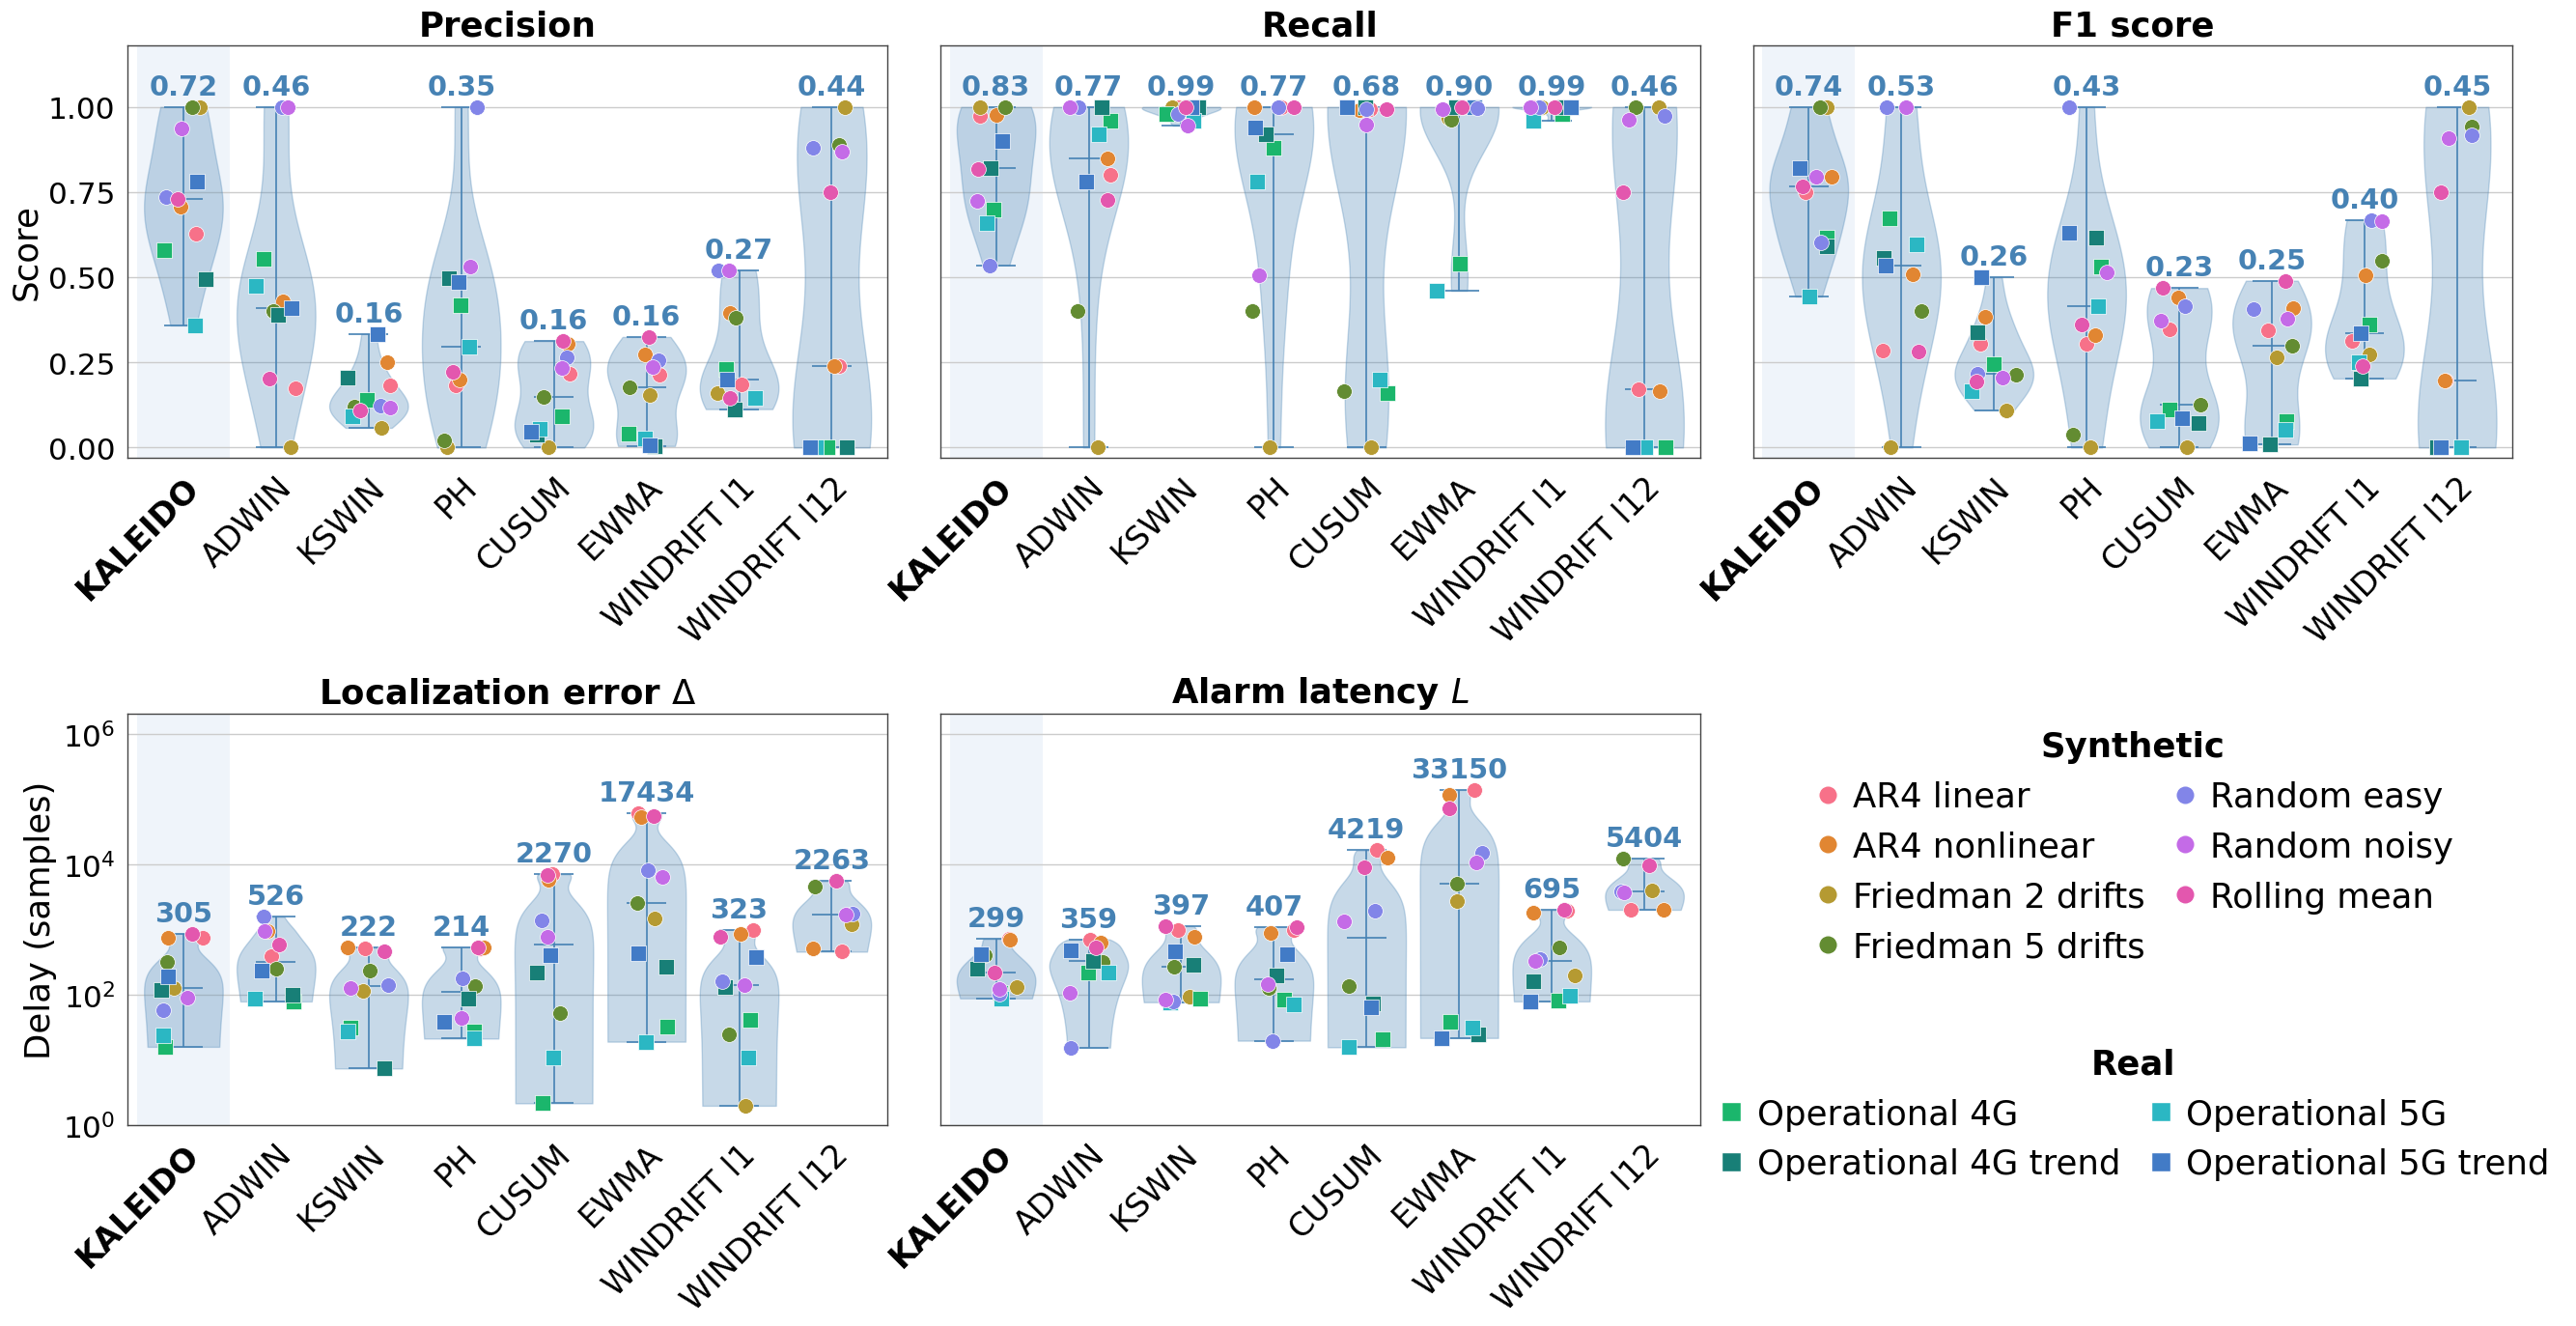

(<Figure size 2600x1300 with 6 Axes>,
 [[<Axes: title={'center': 'Precision'}, ylabel='Score'>,
   <Axes: title={'center': 'Recall'}>,
   <Axes: title={'center': 'F1 score'}>],
  [<Axes: title={'center': 'Localization error $\\Delta$'}, ylabel='Delay (samples)'>,
   <Axes: title={'center': 'Alarm latency $L$'}>]])

In [14]:
number_of_benchmarks = 7
REAL_TS = ["infocom_4G_add_hour", "infocom_4G_add_hour_trend",
           "infocom_5G_add_hour", "infocom_5G_add_hour_trend"]

TS_COLORS = {
    "AR4_linear_1": "#f77189", "AR4_nonlinear_1": "#e18632", "friedman_2_drifts": "#b59a32",
    "friedman_5_drifts": "#638c32", "random_easy": "#8285e8", "random_noisy": "#c46be7",
    "rolling_mean": "#e357ae",
    "infocom_4G_add_hour": "#1bb66c", "infocom_4G_add_hour_trend": "#187f77",
    "infocom_5G_add_hour": "#2bb7c3", "infocom_5G_add_hour_trend": "#427bc6",
}


def plot_metrics_grid(plot_df, plot_dist_df, ylim=None, exclude_ts=None,
                      real_ts=REAL_TS, real_marker="s", synthetic_marker="o",
                      group_labels=("Synthetic", "Real"),
                      save="figures/results.pdf", metric_titles=None, ts_titles=None, model_titles=None,
                      figsize=(26, 13), ncols=3,
                      fontsize=16, tick_fontsize=None, model_fontsize=None, legend_fontsize=None,
                      annot_fontsize=11, text_color="black", violin_color="steelblue", dot_size=60,
                      border_color="#444444", border_width=1.0,
                      wspace=0.07, hspace=0.62, xlabel_rotation=45,
                      legend_markersize=10, legend_colspacing=0.7, legend_titles=True,
                      legend_cols=2,              # columns inside each legend box
                      legend_gap=0.04,            # vertical gap between the two boxes (figure fraction)
                      ylim_delay=None,
                      ylabel_score="Score", ylabel_delay="Delay (samples)", log_headroom=15,
                      bw_method=None, font_scale=1.0, bold_family="DejaVu Sans"):
    """
    Two-row grid: score metrics of plot_df on top (linear axis), delay metrics of plot_dist_df
    below (log axis), legends in the empty bottom-right cell. Model names rotated by
    `xlabel_rotation`. y-axis shared and labelled once per row.
    """
    if exclude_ts:
        plot_df = plot_df[~plot_df["time_series"].isin(exclude_ts)].copy()
        plot_dist_df = plot_dist_df[~plot_dist_df["time_series"].isin(exclude_ts)].copy()

    sns.set_theme(style="whitegrid")                 # resets font.family -> set fonts AFTER this
    tick_fontsize = tick_fontsize or fontsize - 2
    model_fontsize = model_fontsize or fontsize - 1
    legend_fontsize = legend_fontsize or fontsize - 3
    fontsize, tick_fontsize, model_fontsize, legend_fontsize, annot_fontsize = (
        v * font_scale for v in (fontsize, tick_fontsize, model_fontsize, legend_fontsize, annot_fontsize))
    mpl.rcParams.update({
        # "font.family": "serif", "font.serif": ["cmr10"],
        # "mathtext.fontset": "cm", "axes.formatter.use_mathtext": True,
        "font.family": "sans-serif", "font.sans-serif": ["DejaVu Sans"],
        "mathtext.fontset": "dejavusans", "axes.formatter.use_mathtext": False,
        "pdf.fonttype": 42, "ps.fonttype": 42,
        "font.size": fontsize, "axes.labelsize": fontsize, "axes.titlesize": fontsize,
        "xtick.labelsize": model_fontsize, "ytick.labelsize": tick_fontsize,
        "legend.fontsize": legend_fontsize,
        "text.color": text_color, "axes.labelcolor": text_color, "axes.titlecolor": text_color,
        "xtick.color": text_color, "ytick.color": text_color,
    })
    metric_titles = metric_titles or {}
    ts_titles = ts_titles or {}
    model_titles = model_titles or {}
    real_ts = set(real_ts)

    model_order = list(plot_df["model"].dropna().unique())
    lin_metrics = list(plot_df["metric"].dropna().unique())
    log_metrics = list(plot_dist_df["metric"].dropna().unique())

    all_ts = list(pd.unique(pd.concat([plot_df["time_series"], plot_dist_df["time_series"]]).dropna()))
    ts_palette = sns.color_palette("husl", n_colors=len(all_ts))
    ts_colors = {**{ts: ts_palette[i] for i, ts in enumerate(all_ts)}, **TS_COLORS}
    ts_marker = {ts: (real_marker if ts in real_ts else synthetic_marker) for ts in all_ts}
    syn = [ts for ts in all_ts if ts not in real_ts]
    rea = [ts for ts in all_ts if ts in real_ts]

    half = len(model_order) - number_of_benchmarks
    rng = np.random.default_rng(42)

    log_vals = pd.concat([plot_dist_df[plot_dist_df["metric"] == m]["mean"] for m in log_metrics]) \
        if log_metrics else pd.Series(dtype=float)
    log_vals = log_vals[log_vals > 0]
    log_lo, log_hi = (log_vals.min(), log_vals.max()) if len(log_vals) else (1, 10)

    # ---- grid: rows = [scores, delays]; the delay row leaves its last cell(s) for the legends
    rows = [(lin_metrics, plot_df, False, ylabel_score), (log_metrics, plot_dist_df, True, ylabel_delay)]
    rows = [r for r in rows if r[0]]
    ncols = max(ncols, *(len(r[0]) for r in rows))
    fig = plt.figure(figsize=figsize)
    gs = fig.add_gridspec(len(rows), ncols, wspace=wspace, hspace=hspace,
                          left=0.045, right=0.995, top=0.96, bottom=0.1)

    axes = []
    legend_cell = None
    for r, (metrics, df, symlog, ylabel) in enumerate(rows):
        row_axes = []
        for c, metric in enumerate(metrics):
            ax = fig.add_subplot(gs[r, c], sharey=row_axes[0] if row_axes else None)
            row_axes.append(ax)

            if half > 0:
                ax.axvspan(-0.5, half - 0.5, color="#dce8f5", alpha=0.45, zorder=0, lw=0)
            if half < len(model_order):
                ax.axvspan(half - 0.5, len(model_order) - 0.5, color="#ffffff", alpha=0.45, zorder=0, lw=0)

            # if 0 < half < len(model_order):
            #     ax.axvline(half - 0.5, color=border_color, lw=1.0, ls="-", zorder=1)
                
            for j, model in enumerate(model_order):
                means = df[(df["model"] == model) & (df["metric"] == metric)].set_index("time_series")["mean"].dropna()
                if symlog:
                    means = means[means != 0]
                if means.empty:
                    continue
                vals = means.values
                if len(vals) >= 2:
                    parts = ax.violinplot([vals], positions=[j], widths=0.85, showmedians=True,
                                          showextrema=True, bw_method=bw_method)
                    for pc in parts["bodies"]:
                        pc.set_facecolor(violin_color); pc.set_alpha(0.3); pc.set_edgecolor(violin_color)
                    for key in ("cmedians", "cmins", "cmaxes", "cbars"):
                        if key in parts:
                            parts[key].set_color(violin_color); parts[key].set_linewidth(1.2)
                jitter = rng.uniform(-0.25, 0.25, size=len(means))
                for (ts, val), jit in zip(means.items(), jitter):
                    ax.scatter(j + jit, val, color=ts_colors.get(ts, "gray"), marker=ts_marker.get(ts, "o"),
                               s=dot_size, zorder=4, edgecolors="white", linewidths=0.5)
                ax.annotate(f"{vals.mean():{'.0f' if symlog else '.2f'}}", xy=(j, vals.max()),
                            xytext=(0, 5), textcoords="offset points", ha="center", va="bottom",
                            fontsize=annot_fontsize, color=violin_color, fontweight="bold", rotation=0)

            ax.set_title(metric_titles.get(metric, metric), pad=8, fontweight="bold")
            ax.set_xticks(range(len(model_order)))
            ax.set_xticklabels([model_titles.get(m, m) for m in model_order],
                               rotation=xlabel_rotation,
                               ha="right" if 0 < xlabel_rotation < 90 else "center",
                               rotation_mode="anchor" if 0 < xlabel_rotation < 90 else "default")
            for lab in ax.get_xticklabels()[:half]:          # models on the blue band
                lab.set_fontweight("bold")
            ax.set_xlim(-0.6, len(model_order) - 0.4)
            ax.grid(axis="x", visible=False)

            if symlog:
                ax.set_yscale("log")
                ax.set_ylim(*(ylim_delay if ylim_delay is not None else (log_lo / 2, log_hi * log_headroom)))
            else:
                ax.set_ylim(*(ylim if ylim is not None else (-0.03, 1.18)))
            if c == 0:
                ax.set_ylabel(ylabel)
            else:
                ax.tick_params(labelleft=False)
            for sp in ax.spines.values():
                sp.set_visible(True); sp.set_color(border_color); sp.set_linewidth(border_width)
        axes.append(row_axes)
        if len(metrics) < ncols and legend_cell is None:
            legend_cell = gs[r, len(metrics):]              # free cell(s) on this row -> legends

    # ---- legends: two stacked boxes in the free cell (or above the grid if every cell is used)
    def _handles(ts_list):
        return [Line2D([], [], ls="", marker=ts_marker[ts], color=ts_colors[ts], mec="white",
                       ms=legend_markersize, label=ts_titles.get(ts, ts)) for ts in ts_list]

    def _kw(title):
        kw = dict(labelcolor=text_color, frameon=False, edgecolor=border_color, fancybox=False,
                  handlelength=0.9, handletextpad=0.3, columnspacing=legend_colspacing,
                  borderpad=0.5, borderaxespad=0.0, ncols=legend_cols)
        if legend_titles:
            kw.update(title=title, alignment="center",
                      title_fontproperties={"weight": "bold", "size": legend_fontsize})
        return kw

    if legend_cell is not None:
        lax = fig.add_subplot(legend_cell); lax.axis("off")
        x0, y0, x1, y1 = lax.get_position().extents
        xc = (x0 + x1) / 2
        leg1 = fig.legend(handles=_handles(syn), loc="upper center", bbox_to_anchor=(xc, y1),
                          **_kw(group_labels[0]))
        fig.canvas.draw()                                    # need its height to stack the second box
        h1 = leg1.get_window_extent().transformed(fig.transFigure.inverted()).height
        leg2 = fig.legend(handles=_handles(rea), loc="upper center",
                          bbox_to_anchor=(xc, y1 - h1 - legend_gap), **_kw(group_labels[1]))
    else:
        leg1 = fig.legend(handles=_handles(syn), loc="lower left", bbox_to_anchor=(0.045, 0.97), **_kw(group_labels[0]))
        leg2 = fig.legend(handles=_handles(rea), loc="lower right", bbox_to_anchor=(0.995, 0.97), **_kw(group_labels[1]))

    if save:
        plt.savefig(save, bbox_inches="tight")
    plt.show()
    return fig, axes


plot_metrics_grid(
    plot_df, plot_dist_df, ylim=None, exclude_ts=["friedman_no_drifts"], save="figures/results_v3.pdf",
    fontsize=16, annot_fontsize=13, figsize=(26, 13), font_scale=1.6, legend_fontsize=16,
    xlabel_rotation=45,
    dot_size=130, legend_markersize=14,
    ylim_delay=None,
    metric_titles={
        "F1 Score":                               "F1 score",
        "Miss Detection Rate":                    "Miss detection rate",
        "Sum Both Early and Late Detections":     r"Localization error $\Delta$",
        "Sum Both Early and Late Detections end": r"Alarm latency $L$",
    },
    ts_titles={
        "AR4_linear_1":              "AR4 linear",
        "AR4_nonlinear_1":           "AR4 nonlinear",
        "friedman_2_drifts":         "Friedman 2 drifts",
        "friedman_5_drifts":         "Friedman 5 drifts",
        "infocom_4G_add_hour":       "Operational 4G",
        "infocom_4G_add_hour_trend": "Operational 4G trend",
        "infocom_5G_add_hour":       "Operational 5G",
        "infocom_5G_add_hour_trend": "Operational 5G trend",
        "random_easy":               "Random easy",
        "random_noisy":              "Random noisy",
        "rolling_mean":              "Rolling mean",
    },
)

## False alarms

In [15]:
# raw per-run frames, same names and order as `sources`
raw_sources = {
    'KALEIDO':    df_proposal_s_gradient,
    'ADWIN':        df_adwin,
    'KSWIN':        df_kswin,
    'PH':           df_ph,
    'CUSUM':        df_cusum,
    'EWMA':         df_ewma,
    'WINDRIFT l1':  df_windrift,
    'WINDRIFT l12': df_windrift_12,
}
no_drift_ts = 'friedman_no_drifts'

fa_runs = {}                       # model -> array of false alarms per run
for name, df in raw_sources.items():
    d = df[df['time_series'] == no_drift_ts]
    fa_runs[name] = d.sort_values('id')['False Positives'].to_numpy()


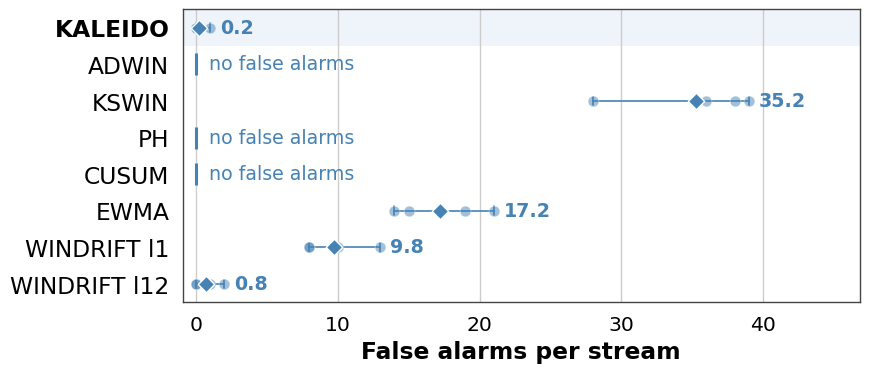

(<Figure size 900x404 with 1 Axes>, <Axes: xlabel='False alarms per stream'>)

In [16]:
def plot_false_alarms(fa_runs, ours="season+gr", save="figures/false_alarms_no_drift.pdf",
                      model_titles=None, title=None, xlabel="False alarms per stream",
                      figsize=None, fontsize=16, tick_fontsize=None, annot_fontsize=None,
                      font_scale=1.0,                        # multiplies every text size, as in the main figure
                      text_color="black", color="steelblue", dot_size=60,
                      border_color="#444444", border_width=1.0,
                      band_ours="#dce8f5", band_bench="#ffffff",
                      bold_family="DejaVu Sans", italic_family="DejaVu Sans"):
    """
    fa_runs : {model: array of false-alarm counts, one per no-drift stream}
    Horizontal version of the candlestick style: one row per model, min–max stem,
    one dot per stream, mean as a diamond with the value annotated.
    Styled like plot_metrics_candlestick: DejaVu Sans text, bordered panel, blue/beige bands for ours vs benchmarks,
    our model's name in bold and a separator line between ours and the benchmarks.
    """
    sns.set_theme(style="whitegrid")                 # resets font.family -> set fonts AFTER this
    tick_fontsize = tick_fontsize or fontsize - 2
    annot_fontsize = annot_fontsize or fontsize - 3
    fontsize, tick_fontsize, annot_fontsize = (v * font_scale for v in (fontsize, tick_fontsize, annot_fontsize))
    mpl.rcParams.update({
        # "font.family": "serif", "font.serif": ["cmr10"],
        # "mathtext.fontset": "cm", "axes.formatter.use_mathtext": True,   # CM math + proper minus signs
        "font.family": "sans-serif", "font.sans-serif": ["DejaVu Sans"],
        "mathtext.fontset": "dejavusans", "axes.formatter.use_mathtext": False,
        "pdf.fonttype": 42, "ps.fonttype": 42,
        "font.size": fontsize, "axes.labelsize": fontsize, "axes.titlesize": fontsize,
        "xtick.labelsize": tick_fontsize, "ytick.labelsize": fontsize,
        "text.color": text_color, "axes.labelcolor": text_color, "axes.titlecolor": text_color,
        "xtick.color": text_color, "ytick.color": text_color,
    })
    model_titles = model_titles or {}

    models = list(fa_runs)                       # keep dict order (ours first)
    n_ours = sum(1 for m in models if m == ours)
    xmax = max(np.max(v) for v in fa_runs.values())
    xlim = xmax * 1.2 if xmax > 0 else 1

    fig, ax = plt.subplots(figsize=figsize or (9, 0.55 * len(models) + 1.2))

    # background bands: ours (blue) vs benchmarks (beige), as in the main figure
    ax.axhspan(-0.5, n_ours - 0.5, color=band_ours, alpha=0.45, zorder=0, lw=0)
    ax.axhspan(n_ours - 0.5, len(models) - 0.5, color=band_bench, alpha=0.45, zorder=0, lw=0)
    # if 0 < n_ours < len(models):                 # separator between ours and the benchmarks
    #     ax.axhline(n_ours - 0.5, color=border_color, lw=1.0, ls="-", zorder=1)

    for i, m in enumerate(models):
        vals = np.asarray(fa_runs[m], dtype=float)

        if vals.max() == 0:
            ax.plot([0], [i], marker="|", ms=16, mew=2.2, color=color, zorder=3)
            ax.text(xlim * 0.02, i, "no false alarms", va="center", fontsize=annot_fontsize,
                    color=color, zorder=4)
            continue

        # min–max stem with caps (like the violin extrema)
        ax.plot([vals.min(), vals.max()], [i, i], color=color, lw=1.2, zorder=2)
        for v in (vals.min(), vals.max()):
            ax.plot([v, v], [i - 0.12, i + 0.12], color=color, lw=1.2, zorder=2)
        # one dot per stream
        ax.scatter(vals, [i] * len(vals), s=dot_size, color=color, alpha=0.5,
                   edgecolors="white", linewidths=0.5, zorder=3)
        # mean
        ax.scatter([vals.mean()], [i], marker="D", s=dot_size + 10, color=color,
                   edgecolors="white", linewidths=1, zorder=4)
        ax.annotate(f"{vals.mean():.1f}", xy=(vals.max(), i), xytext=(7, 0),
                    textcoords="offset points", ha="left", va="center",
                    fontsize=annot_fontsize, color=color, fontweight="bold")

    ax.set_yticks(range(len(models)))
    ax.set_yticklabels([model_titles.get(m, m) for m in models])
    for lab in ax.get_yticklabels()[:n_ours]:    # our model(s): bold name
        lab.set_fontweight("bold")
    ax.set_ylim(len(models) - 0.5, -0.5)
    ax.set_xlim(-xlim * 0.02, xlim)
    ax.set_xlabel(xlabel, fontweight="bold")
    ax.grid(axis="y", visible=False)

    if title:
        ax.set_title(title, pad=8, fontweight="bold")

    # clear borders on all four sides, as in the main figure
    for sp in ax.spines.values():
        sp.set_visible(True); sp.set_color(border_color); sp.set_linewidth(border_width)

    plt.tight_layout()
    if save:
        plt.savefig(save, bbox_inches="tight")
    plt.show()
    return fig, ax


plot_false_alarms(fa_runs, ours="KALEIDO", save="figures/false_alarms_no_drift.pdf",
                  font_scale=1.05,                  # same text scaling as the main figure
                  figsize=(9, 0.38 * len(fa_runs) + 1.0),
                  # model_titles={"season+gr": "Ours", "WINDRIFT l1": "WinDrift (L1)", "WINDRIFT l12": "WinDrift (L12)"},
                  )

In [17]:
recall_ts = 'friedman_2_drifts'

recall_runs = {}                   # model -> array of recall per run
for name, df in raw_sources.items():
    d = df[df['time_series'] == recall_ts]
    recall_runs[name] = d.sort_values('id')['Recall'].to_numpy()

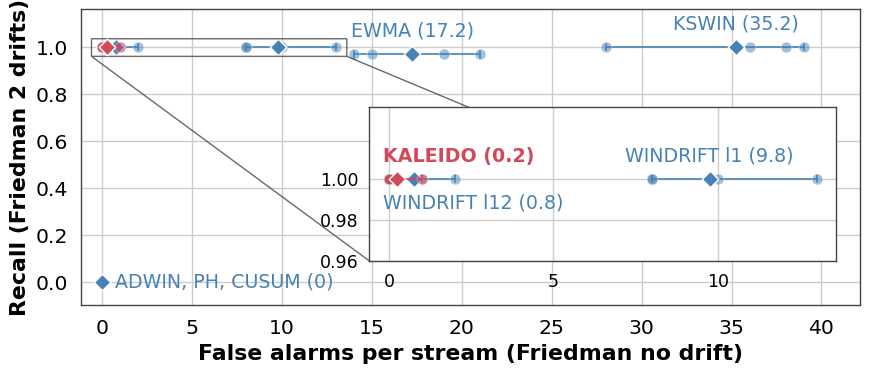

(<Figure size 900x404 with 1 Axes>,
 (<Axes: xlabel='False alarms per stream (Friedman no drift)', ylabel='Recall (Friedman 2 drifts)'>,
  <Axes: label='inset_axes'>))

In [50]:
def plot_fa_vs_recall(fa_runs, recall_runs, ours="KALEIDO", save="figures/fa_vs_recall_friedman.pdf",
                      model_titles=None, title=None,
                      xlabel="False alarms per stream (Friedman no drift)",
                      ylabel="Recall (Friedman 2 drifts)",
                      figsize=None, fontsize=16, tick_fontsize=None, annot_fontsize=None,
                      font_scale=1.0, text_color="black",
                      color="steelblue", color_ours="#d1495b", dot_size=60,
                      show_runs=True,                       # False: only the mean diamonds (no stems, no dots)
                      show_mean=True, mean_fmt="{:.1f}",    # mean false alarms after the name, e.g. "EWMA (17.2)"
                      label_pos=None,                       # {model: "above" | "below" | "right"}
                      zoom_x=(0, 15), zoom_y=(0.9, 1.0),    # region shown in the inset (None, None: no inset)
                      zoom_pad=(0.6, 0.035),                # margin around the region so markers/labels are not cut
                      inset_bounds=(0.37, 0.15, 0.60, 0.52),  # x0, y0, width, height in axes fraction
                      border_color="#444444", border_width=1.0):
    """
    Scatter plot in the style of plot_false_alarms, one diamond per model:
      x = mean false alarms on the drift-free stream (min–max stem and one dot per stream if show_runs),
      y = mean recall on the two-drift stream.
    Linear axes, every point at its true value; top-left is best.
    An inset zooms on the crowded top-left corner; models inside it are labelled there,
    the others are labelled on the main axes.
    Models with identical statistics (e.g. 0 alarms / 0 recall) share one diamond and one label.
    Same figure size and single colour as plot_false_alarms; our model is marked by its bold label
    (pass color_ours to give it its own colour).
    """
    sns.set_theme(style="whitegrid")
    tick_fontsize = tick_fontsize or fontsize - 2
    annot_fontsize = annot_fontsize or fontsize - 3
    fontsize, tick_fontsize, annot_fontsize = (v * font_scale for v in (fontsize, tick_fontsize, annot_fontsize))
    mpl.rcParams.update({
        "font.family": "sans-serif", "font.sans-serif": ["DejaVu Sans"],
        "mathtext.fontset": "dejavusans", "axes.formatter.use_mathtext": False,
        "pdf.fonttype": 42, "ps.fonttype": 42,
        "font.size": fontsize, "axes.labelsize": fontsize, "axes.titlesize": fontsize,
        "xtick.labelsize": tick_fontsize, "ytick.labelsize": tick_fontsize,
        "text.color": text_color, "axes.labelcolor": text_color, "axes.titlecolor": text_color,
        "xtick.color": text_color, "ytick.color": text_color,
    })
    model_titles = model_titles or {}
    color_ours = color_ours or color
    # where each label goes relative to its stem; anything not listed goes to the right
    label_pos = {"KALEIDO": "above", "WINDRIFT l12": "below", "WINDRIFT l1": "above",
                 "EWMA": "below", "KSWIN": "above", **(label_pos or {})}
    zoom = zoom_x is not None and zoom_y is not None

    # ---- group models whose statistics coincide
    groups = {}
    for m in fa_runs:
        if m not in recall_runs or len(recall_runs[m]) == 0:
            continue
        x = np.asarray(fa_runs[m], dtype=float)
        y = np.asarray(recall_runs[m], dtype=float)
        key = (round(x.mean(), 6), round(x.min(), 6), round(x.max(), 6),
               round(y.mean(), 6), round(y.min(), 6), round(y.max(), 6))
        g = groups.setdefault(key, {"models": [], "x": x, "y": y})
        g["models"].append(m)
    for g in groups.values():
        xm, ym = g["x"].mean(), g["y"].mean()
        g["in_zoom"] = zoom and zoom_x[0] <= xm <= zoom_x[1] and zoom_y[0] <= ym <= zoom_y[1]

    def _draw(a, g, cap, with_label):
        x, y, models = g["x"], g["y"], g["models"]
        is_ours = ours in models
        c = color_ours if is_ours else color
        z = 10 if is_ours else 2                  # ours on top
        xm, ym = x.mean(), y.mean()

        if show_runs:
            if x.max() > x.min():                 # min–max stem with caps
                a.plot([x.min(), x.max()], [ym, ym], color=c, lw=1.2, zorder=z)
                for v in (x.min(), x.max()):
                    a.plot([v, v], [ym - cap, ym + cap], color=c, lw=1.2, zorder=z)
            a.scatter(x, [ym] * len(x), s=dot_size, color=c, alpha=0.5,
                      edgecolors="white", linewidths=0.5, zorder=z + 1)
        a.scatter([xm], [ym], marker="D", s=dot_size + 10, color=c,
                  edgecolors="white", linewidths=1, zorder=z + 2)
        if not with_label:
            return

        label = ", ".join(model_titles.get(m, m) for m in models)
        if show_mean:
            label += f" ({'0' if xm == 0 else mean_fmt.format(xm)})"
        kw = dict(textcoords="offset points", fontsize=annot_fontsize, color=c, zorder=20,
                  fontweight="bold" if is_ours else "normal", annotation_clip=False)
        pos = label_pos.get(models[0], "right")
        lo, hi = a.get_xlim()
        near_edge = (xm - lo) < 0.12 * (hi - lo)  # near the left edge: start at the stem, not centred
        anchor = (x.min() if show_runs else xm) if near_edge else xm
        if pos == "above":
            a.annotate(label, xy=(anchor, ym), xytext=(-4 if near_edge else 0, 10),
                       ha="left" if near_edge else "center", va="bottom", **kw)
        elif pos == "below":
            a.annotate(label, xy=(anchor, ym), xytext=(-4 if near_edge else 0, -10),
                       ha="left" if near_edge else "center", va="top", **kw)
        else:
            a.annotate(label, xy=(x.max() if show_runs else xm, ym), xytext=(9, 0),
                       ha="left", va="center", **kw)

    # ---- main axes
    xmax = max(g["x"].max() for g in groups.values())
    fig, ax = plt.subplots(figsize=figsize or (9, 0.38 * len(fa_runs) + 1.0))   # same size as plot_false_alarms
    ax.set_xlim(-max(xmax, 1) * 0.03, max(xmax, 1) * 1.08)
    ax.set_ylim(-0.1, 1.16)
    ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
    for g in groups.values():
        _draw(ax, g, cap=0.014, with_label=not g["in_zoom"])
    ax.set_xlabel(xlabel, fontweight="bold", fontsize=fontsize-1)
    ax.set_ylabel(ylabel, fontweight="bold", fontsize=fontsize-1)
    if title:
        ax.set_title(title, pad=8, fontweight="bold")
    for sp in ax.spines.values():
        sp.set_visible(True); sp.set_color(border_color); sp.set_linewidth(border_width)

    # ---- inset: zoom on the top-left corner
    axins = None
    if zoom:
        axins = ax.inset_axes(inset_bounds)
        axins.set_xlim(zoom_x[0] - zoom_pad[0], zoom_x[1] + zoom_pad[0])
        axins.set_ylim(zoom_y[0], zoom_y[1] + zoom_pad[1])
        span = axins.get_ylim()[1] - axins.get_ylim()[0]
        for g in groups.values():
            _draw(axins, g, cap=0.022 * span, with_label=g["in_zoom"])
        axins.set_xticks(np.arange(zoom_x[0], zoom_x[1] + 1, 5))
        axins.set_yticks(np.linspace(zoom_y[0], zoom_y[1], 3))
        axins.tick_params(labelsize=tick_fontsize * 0.85, pad=2)
        axins.set_facecolor("white")
        for sp in axins.spines.values():
            sp.set_visible(True); sp.set_color(border_color); sp.set_linewidth(border_width)
        ax.indicate_inset_zoom(axins, edgecolor=border_color, alpha=0.8, lw=border_width)

    plt.tight_layout()
    if save:
        plt.savefig(save, bbox_inches="tight")
    plt.show()
    return fig, (ax, axins)


plot_fa_vs_recall(fa_runs, recall_runs, ours="KALEIDO", save="figures/fa_vs_recall_friedman.pdf",
                  font_scale=1.05,
                  zoom_x=(0, 13), 
                  zoom_y=(0.96, 1.0),              
                  label_pos={"EWMA": "above"}) 